# Delivery Time Prediction - Olist (Linear Regression)

Three parts: **Part 1** prepare clean data → **Part 2** prepare X, y and train/test → **Part 3** run the model.


## PART 1: Prepare clean data
### Cell 1: Download data from Kaggle and read the tables

In [1]:
# Install the library for downloading data from Kaggle
!pip install -q kagglehub statsmodels

import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import kagglehub
import statsmodels.api as sm
from statsmodels.stats.outliers_influence import variance_inflation_factor
from scipy import stats
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.pipeline import make_pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

# Folder for saving charts and result tables for the report
os.makedirs('figures', exist_ok=True)

# Download the Olist dataset
path = kagglehub.dataset_download("olistbr/brazilian-ecommerce")
print("Data directory:", path)

# Read 8 tables. order_reviews is used only for EDA (the motivation for the problem), NOT put into X because it only exists after delivery.
# The category_translation table is not used yet because there is no product category feature yet.
orders      = pd.read_csv(os.path.join(path, 'olist_orders_dataset.csv'))
order_items = pd.read_csv(os.path.join(path, 'olist_order_items_dataset.csv'))
payments    = pd.read_csv(os.path.join(path, 'olist_order_payments_dataset.csv'))
customers   = pd.read_csv(os.path.join(path, 'olist_customers_dataset.csv'))
products    = pd.read_csv(os.path.join(path, 'olist_products_dataset.csv'))
sellers     = pd.read_csv(os.path.join(path, 'olist_sellers_dataset.csv'))
geolocation = pd.read_csv(os.path.join(path, 'olist_geolocation_dataset.csv'))
reviews     = pd.read_csv(os.path.join(path, 'olist_order_reviews_dataset.csv'))

print("orders:", orders.shape)
orders.head(2)


[notice] A new release of pip is available: 26.2.2 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


100%|██████████| 42.6M/42.6M [00:06<00:00, 7.16MB/s]

Extracting files...


Data directory: C:\Users\hello\.cache\kagglehub\datasets\olistbr\brazilian-ecommerce\versions\2
orders: (99441, 8)


,order_id,customer_id,order_status,order_purchase_timestamp,order_approved_at,order_delivered_carrier_date,order_delivered_customer_date,order_estimated_delivery_date
0,e481f51cbdc54678b7cc49136f2d6af7,9ef432eb6251297304e76186b10a928d,delivered,2017-10-02 10:56:33,2017-10-02 11:07:15,2017-10-04 19:55:00,2017-10-10 21:25:13,2017-10-18 00:00:00
1,53cdb2fc8bc7dce0b6741e2150273451,b0830fb4747a6c6d20dea0b8c802d7ef,delivered,2018-07-24 20:41:37,2018-07-26 03:24:27,2018-07-26 14:31:00,2018-08-07 15:27:45,2018-08-13 00:00:00


### Cell 1b: Raw table statistics (Table 1) and order status distribution
Run **before** cleaning (Cell 2 drops duplicates and filters `orders`). Gives the raw rows, columns, missing values and duplicate rows of each table, and the `order_status` breakdown used to explain why 2,963 orders are removed.

In [2]:
# category_translation is not used in X, it is read only so that Table 1 is complete
category_translation = pd.read_csv(os.path.join(path, 'product_category_name_translation.csv'))

raw_tables = {'orders': orders, 'order_items': order_items, 'payments': payments,
              'customers': customers, 'products': products, 'sellers': sellers,
              'geolocation': geolocation, 'reviews': reviews,
              'category_translation': category_translation}

# Table 1: dimensions, missing cells (total NaN cells) and duplicate rows of the RAW tables
raw_summary = pd.DataFrame([{
    'Table': name,
    'Row Count': d.shape[0],
    'Column Count': d.shape[1],
    'Missing Values': int(d.isna().sum().sum()),
    'Duplicate Rows': int(d.duplicated().sum())
} for name, d in raw_tables.items()])
raw_summary.to_csv('figures/table1_raw_tables.csv', index=False)
print(raw_summary.to_string(index=False, formatters={c: '{:,}'.format for c in
                                                     ['Row Count', 'Missing Values', 'Duplicate Rows']}))

print(f"\ngeolocation after dropping duplicates: {len(geolocation.drop_duplicates()):,} rows "
      f"(= {len(geolocation):,} - {geolocation.duplicated().sum():,})")

# order_status distribution (raw orders) and the duplicate check for orders
print("\nDuplicate rows in orders:", int(orders.duplicated().sum()))
status_counts = orders['order_status'].value_counts()
print("\norder_status distribution (raw orders):")
print(status_counts.to_string())
not_delivered = status_counts.drop('delivered')
print(f"\nOrders removed because status != delivered: {not_delivered.sum():,}")
print(not_delivered.to_string())

               Table Row Count  Column Count Missing Values Duplicate Rows
              orders    99,441             8          4,908              0
         order_items   112,650             7              0              0
            payments   103,886             5              0              0
           customers    99,441             5              0              0
            products    32,951             9          2,448              0
             sellers     3,095             4              0              0
         geolocation 1,000,163             5              0        261,831
             reviews    99,224             7        145,903              0
category_translation        71             2              0              0

geolocation after dropping duplicates: 738,332 rows (= 1,000,163 - 261,831)

Duplicate rows in orders: 0

order_status distribution (raw orders):
order_status
delivered      96478
shipped         1107
canceled         625
unavailable      609
invoic

### Cell 2: Clean the tables
Drop duplicate rows, convert dates, keep only `delivered` orders.
Missing product values (weight, dimensions) are **not imputed here**: they will be imputed with the train-set median in the Pipeline in Part 3.

In [3]:
# Cleaning log: record the number of orders at each step to build a table for the report (see Cell 7)
cleaning_log = []
def log_step(step, removed, remaining):
    cleaning_log.append({'Step': step, 'Orders removed': removed, 'Orders remaining': remaining})

# ---------- orders ----------
n_raw = len(orders)
log_step('Raw data (orders)', 0, n_raw)

orders = orders.drop_duplicates()
orders = orders[orders['order_status'] == 'delivered'].copy()      # keep only delivered orders
log_step('Drop duplicate rows, keep only delivered orders', n_raw - len(orders), len(orders))

date_cols = ['order_purchase_timestamp', 'order_approved_at',
             'order_delivered_carrier_date', 'order_delivered_customer_date',
             'order_estimated_delivery_date']
for col in date_cols:
    orders[col] = pd.to_datetime(orders[col])                      # convert to datetime

n_before = len(orders)
orders = orders.dropna(subset=['order_delivered_customer_date'])   # drop if the actual delivery date is missing
log_step('Drop delivered orders missing the actual delivery date', n_before - len(orders), len(orders))
print(f"Dropped {n_before - len(orders)} delivered orders missing the actual delivery date")

# ---------- order_items ----------
order_items = order_items.drop_duplicates()
order_items['shipping_limit_date'] = pd.to_datetime(order_items['shipping_limit_date'])
order_items = order_items.dropna(subset=['order_id', 'product_id', 'seller_id'])

# ---------- payments, customers, sellers, products, geolocation ----------
payments    = payments.drop_duplicates().dropna(subset=['order_id'])
customers   = customers.drop_duplicates()
sellers     = sellers.drop_duplicates()
products    = products.drop_duplicates()
geolocation = geolocation.drop_duplicates()
reviews     = reviews.drop_duplicates()

# ---------- quick check ----------
for name, d in [('orders', orders), ('order_items', order_items), ('payments', payments),
                ('customers', customers), ('products', products),
                ('sellers', sellers), ('geolocation', geolocation), ('reviews', reviews)]:
    print(f"{name:12s} {d.shape}")

Dropped 8 delivered orders missing the actual delivery date
orders       (96470, 8)
order_items  (112650, 7)
payments     (103886, 5)
customers    (99441, 5)
products     (32951, 9)
sellers      (3095, 4)
geolocation  (738332, 5)
reviews      (99224, 7)


### Cell 3: Merge tables to the order level (each row = 1 order)
Aggregate `order_items` and `payments` by `order_id` **first**, then join. Use `assert` to make sure the join does not change the number of rows.

In [4]:
# Aggregate order_items to the order level
items_agg = order_items.groupby('order_id').agg(
    total_price=('price', 'sum'),            # total merchandise value
    total_freight=('freight_value', 'sum'),  # total shipping fee
    item_count=('order_item_id', 'count')    # number of items
).reset_index()

# Aggregate payments to the order level
payments_agg = payments.groupby('order_id').agg(
    total_payment=('payment_value', 'sum')   # total amount paid (for checking only, not put into X)
).reset_index()

# customer_id is a per-order ID so it must be unique, otherwise the join would multiply rows
assert customers['customer_id'].is_unique

n_orders = len(orders)
df = orders.copy()
print("orders (delivered):", len(df))

df = df.merge(items_agg, on='order_id', how='left')
assert len(df) == n_orders
print("after joining items_agg:", len(df))

df = df.merge(payments_agg, on='order_id', how='left')
assert len(df) == n_orders
print("after joining payments_agg:", len(df))

df = df.merge(customers[['customer_id', 'customer_zip_code_prefix', 'customer_state']],
              on='customer_id', how='left')
assert len(df) == n_orders
print("after joining customers:", len(df))

# Orders with no items have no price or shipping fee information: drop them entirely instead of filling in fake numbers
n_no_items = df['total_price'].isna().sum()
df = df.dropna(subset=['total_price']).copy()
log_step('Drop orders with no items (order_items)', n_no_items, len(df))
print(f"\nDropped {n_no_items} orders with no rows in order_items -> {len(df)} orders remaining")

print("\nRemaining missing values:")
print(df[['total_price', 'total_freight', 'item_count', 'total_payment', 'customer_state']].isnull().sum())

orders (delivered): 96470
after joining items_agg: 96470
after joining payments_agg: 96470
after joining customers: 96470

Dropped 0 orders with no rows in order_items -> 96470 orders remaining

Remaining missing values:
total_price       0
total_freight     0
item_count        0
total_payment     1
customer_state    0
dtype: int64


## PART 2: Prepare X, y and the train/test sets
### Cell 4: Create the y variable (`delivery_days`) and remove outliers

In [5]:
# y = number of days from placing the order to receiving it
df['delivery_days'] = (df['order_delivered_customer_date'] -
                       df['order_purchase_timestamp']).dt.total_seconds() / 86400

n0 = len(df)
df = df[df['delivery_days'] > 0]                       # remove negative or zero values
n1 = len(df)

# Remove extreme outliers: keep only the 1st to 99th percentile
low, high = df['delivery_days'].quantile([0.01, 0.99])
df = df[(df['delivery_days'] >= low) & (df['delivery_days'] <= high)].copy()

log_step('Remove orders with delivery_days <= 0', n0 - n1, n1)
log_step('Remove outliers outside the 1%-99% percentile range of y', n1 - len(df), len(df))
print(f"Removed {n0 - n1} orders with y <= 0; removed {n1 - len(df)} orders outside the range [{low:.1f}, {high:.1f}] days")
print("Orders remaining:", len(df))
print(df['delivery_days'].describe())
# Note for the report: the model is evaluated only on the distribution trimmed to 1%-99%

Removed 0 orders with y <= 0; removed 1930 orders outside the range [1.8, 46.1] days
Orders remaining: 94540
count    94540.000000
mean        12.160730
std          7.705163
min          1.825417
25%          6.838328
50%         10.217477
75%         15.458759
max         46.048461
Name: delivery_days, dtype: float64


### Cell 5: Distance feature (Haversine) and same-state flag
- Coordinates outside Brazil's territory are noise and are therefore filtered out; coordinates per zip prefix use the **median**.
- Multi-seller orders: distance takes the **max** (an order is only complete when the farthest item arrives), `same_state` takes the **min** (= 1 only when every item is in the same state as the customer), so it is always a 0/1 flag.

In [6]:
# Filter out coordinates outside Brazil (lat ~ -34..6, lng ~ -74..-34)
in_brazil = (geolocation['geolocation_lat'].between(-34, 6) &
             geolocation['geolocation_lng'].between(-74, -34))
print(f"Removed {(~in_brazil).sum()} geolocation points outside Brazil")

# Median coordinates by area code (zip prefix)
geo = (geolocation[in_brazil]
       .groupby('geolocation_zip_code_prefix')
       .agg(lat=('geolocation_lat', 'median'), lng=('geolocation_lng', 'median'))
       .reset_index())

# Coordinates of customers and sellers
cust_geo = (customers.merge(geo, left_on='customer_zip_code_prefix',
                            right_on='geolocation_zip_code_prefix', how='left')
            [['customer_id', 'customer_state', 'lat', 'lng']]
            .rename(columns={'lat': 'cust_lat', 'lng': 'cust_lng'}))

sell_geo = (sellers.merge(geo, left_on='seller_zip_code_prefix',
                          right_on='geolocation_zip_code_prefix', how='left')
            [['seller_id', 'seller_state', 'lat', 'lng']]
            .rename(columns={'lat': 'sell_lat', 'lng': 'sell_lng'}))

# Haversine formula: distance (km) between 2 points given longitude and latitude
def haversine(lat1, lon1, lat2, lon2):
    lat1, lon1, lat2, lon2 = map(np.radians, [lat1, lon1, lat2, lon2])
    a = np.sin((lat2 - lat1) / 2) ** 2 + np.cos(lat1) * np.cos(lat2) * np.sin((lon2 - lon1) / 2) ** 2
    return 6371 * 2 * np.arcsin(np.sqrt(a))

# Each row = 1 item. Use a left join so rows are NOT silently lost, then check
items = order_items[['order_id', 'seller_id']].merge(df[['order_id', 'customer_id']], on='order_id', how='inner')
n_items = len(items)
items = items.merge(cust_geo, on='customer_id', how='left')
items = items.merge(sell_geo, on='seller_id', how='left')
assert len(items) == n_items, "join changed the number of rows"

items['distance_km'] = haversine(items['cust_lat'], items['cust_lng'],
                                 items['sell_lat'], items['sell_lng'])
items['same_state'] = (items['customer_state'] == items['seller_state']).astype(int)

print(f"Number of items: {n_items}; missing distance: {items['distance_km'].isna().sum()} items")

# Aggregate to the order level
geo_features = items.groupby('order_id').agg(
    distance_km=('distance_km', 'max'),
    same_state=('same_state', 'min')
).reset_index()

print(geo_features.describe())

Removed 33 geolocation points outside Brazil
Number of items: 108005; missing distance: 524 items
        distance_km    same_state
count  94075.000000  94540.000000
mean     602.696322      0.354823
std      588.900599      0.478462
min        0.000000      0.000000
25%      199.374012      0.000000
50%      438.168264      0.000000
75%      800.359319      1.000000
max     3398.548220      1.000000


### Cell 6: Weight, volume, time features and assembling the X, y tables
Use only information **known at the moment of ordering**.
- `order_delivered_*` is excluded because it is only known after delivery (clear leakage).
- `order_estimated_delivery_date`: in terms of timing, Olist computes it right when the order is placed, but it is itself a ready-made delivery time prediction. Putting it into X would turn the problem into "predicting a prediction", so it is deliberately excluded.
- Month, day of week and customer state are **categorical** variables, so they are one-hot encoded instead of being kept as numbers.

In [7]:
# Product volume = length x height x width (missing values left as NaN, to be imputed in the Pipeline)
products['volume_cm3'] = (products['product_length_cm'] *
                          products['product_height_cm'] *
                          products['product_width_cm'])

# TOTAL weight and volume of the items in the order (min_count=1: if every item is missing, keep NaN)
prod_features = (order_items[['order_id', 'product_id']]
                 .merge(products[['product_id', 'product_weight_g', 'volume_cm3']], on='product_id', how='left')
                 .groupby('order_id')[['product_weight_g', 'volume_cm3']].sum(min_count=1)
                 .rename(columns={'product_weight_g': 'weight_total_g',
                                  'volume_cm3': 'volume_total_cm3'})
                 .reset_index())

# Time features
df['purchase_month'] = df['order_purchase_timestamp'].dt.month
df['purchase_dayofweek'] = df['order_purchase_timestamp'].dt.dayofweek

# Combine everything into 1 table, check the row count
n = len(df)
model_df = df.merge(geo_features, on='order_id', how='left')
assert len(model_df) == n
model_df = model_df.merge(prod_features, on='order_id', how='left')
assert len(model_df) == n

# Drop orders whose distance cannot be computed (missing coordinates), do not fill in fake numbers
n_no_dist = model_df['distance_km'].isna().sum()
model_df = model_df.dropna(subset=['distance_km']).reset_index(drop=True)
log_step('Drop orders missing distance (missing coordinates)', n_no_dist, len(model_df))
print(f"Dropped {n_no_dist} orders missing distance -> {len(model_df)} orders remaining")

# Numeric variables
numeric_features = ['distance_km', 'same_state', 'weight_total_g', 'volume_total_cm3',
                    'total_freight', 'total_price', 'item_count']

# Categorical variables -> one-hot (drop 1 level as the reference to avoid perfect multicollinearity)
dummies = pd.get_dummies(
    model_df[['customer_state', 'purchase_month', 'purchase_dayofweek']].astype('category'),
    prefix=['state', 'month', 'dow'], drop_first=True, dtype=int)

X = pd.concat([model_df[numeric_features], dummies], axis=1)
y = model_df['delivery_days']

print("\nMissing values in X (to be imputed with the train-set median in the Pipeline):")
print(X.isnull().sum()[X.isnull().sum() > 0])
print("\nShape of X:", X.shape, "| y:", y.shape)
X.head()

Dropped 465 orders missing distance -> 94075 orders remaining

Missing values in X (to be imputed with the train-set median in the Pipeline):
weight_total_g      16
volume_total_cm3    16
dtype: int64

Shape of X: (94075, 50) | y: (94075,)


,distance_km,same_state,weight_total_g,volume_total_cm3,total_freight,total_price,item_count,state_AL,state_AM,state_AP,...,month_9,month_10,month_11,month_12,dow_1,dow_2,dow_3,dow_4,dow_5,dow_6
0,18.676576,1,500.0,1976.0,8.72,29.99,1,0,0,0,...,0,1,0,0,0,0,0,0,0,0
1,861.068703,0,400.0,4693.0,22.76,118.70,1,0,0,0,...,0,0,0,0,1,0,0,0,0,0
2,514.535098,0,420.0,9576.0,19.22,159.90,1,0,0,0,...,0,0,0,0,0,1,0,0,0,0
3,1821.871635,0,450.0,6000.0,27.20,45.00,1,0,0,0,...,0,0,1,0,0,0,0,0,1,0
4,29.623195,1,250.0,11475.0,8.72,19.90,1,0,0,0,...,0,0,0,0,1,0,0,0,0,0


### Cell 6b: Consistency check of `total_payment`, time coverage of the data
- `total_payment` is **not** in X. It is only checked against `total_price + total_freight`.
- Time coverage shows which months/years are observed (needed to interpret the `month_*` coefficients) and the distance quartiles.

In [8]:
# ---------- 1) total_payment vs total_price + total_freight (final 94,075 orders) ----------
expected = model_df['total_price'] + model_df['total_freight']
gap = (model_df['total_payment'] - expected).abs()
n_no_payment = int(model_df['total_payment'].isna().sum())
within_1 = gap <= 1                                   # NaN gap -> False (counted as exception)
n_exc = int((~within_1).sum())
print(f"Orders: {len(model_df):,}")
print(f"total_payment within 1 BRL of total_price + total_freight: {within_1.sum():,} ({within_1.mean():.1%})")
print(f"Exceptions: {n_exc:,} (of which {n_no_payment} have no payment record)")
print(f"Largest gap: {gap.max():.2f} BRL")

# ---------- 2) time coverage ----------
ts = model_df['order_purchase_timestamp']
print(f"\nPurchase dates: {ts.min():%Y-%m-%d} -> {ts.max():%Y-%m-%d}")
print("\nOrders per year:")
print(ts.dt.year.value_counts().sort_index().to_string())
print("\nOrders per month x year (shows which months exist only in some years):")
print(pd.crosstab(ts.dt.month.rename('month'), ts.dt.year.rename('year')).to_string())

# ---------- 3) distance quartiles ----------
print("\ndistance_km quartiles (25% / 50% / 75%):",
      model_df['distance_km'].quantile([0.25, 0.5, 0.75]).round(0).tolist())

Orders: 94,075
total_payment within 1 BRL of total_price + total_freight: 93,838 (99.7%)
Exceptions: 237 (of which 0 have no payment record)
Largest gap: 182.81 BRL

Purchase dates: 2016-10-03 -> 2018-08-28

Orders per year:
order_purchase_timestamp
2016      258
2017    42488
2018    51329

Orders per month x year (shows which months exist only in some years):
year   2016  2017  2018
month                  
1         0   734  6905
2         0  1636  6296
3         0  2496  6760
4         0  2267  6629
5         0  3463  6593
6         0  3064  5930
7         0  3795  6027
8         0  4113  6189
9         0  4069     0
10      257  4394     0
11        0  7099     0
12        1  5358     0

distance_km quartiles (25% / 50% / 75%): [199.0, 438.0, 800.0]


### Cell 7: Table of the data cleaning process
Collect the number of orders at each step into one table to include in the data description section of the report.

In [9]:
cleaning_table = pd.DataFrame(cleaning_log)
cleaning_table.to_csv('figures/cleaning_table.csv', index=False)
print(cleaning_table.to_string(index=False))
print(f"\nOf the {cleaning_table['Orders remaining'].iloc[0]} original orders, {len(model_df)} orders "
      f"({len(model_df) / cleaning_table['Orders remaining'].iloc[0]:.1%}) are used for the model")

                                                    Step  Orders removed  Orders remaining
                                       Raw data (orders)               0             99441
         Drop duplicate rows, keep only delivered orders            2963             96478
  Drop delivered orders missing the actual delivery date               8             96470
                 Drop orders with no items (order_items)               0             96470
                   Remove orders with delivery_days <= 0               0             96470
Remove outliers outside the 1%-99% percentile range of y            1930             94540
      Drop orders missing distance (missing coordinates)             465             94075

Of the 99441 original orders, 94075 orders (94.6%) are used for the model


### Cell 8: EDA - distribution of y, correlation, delivery time by state

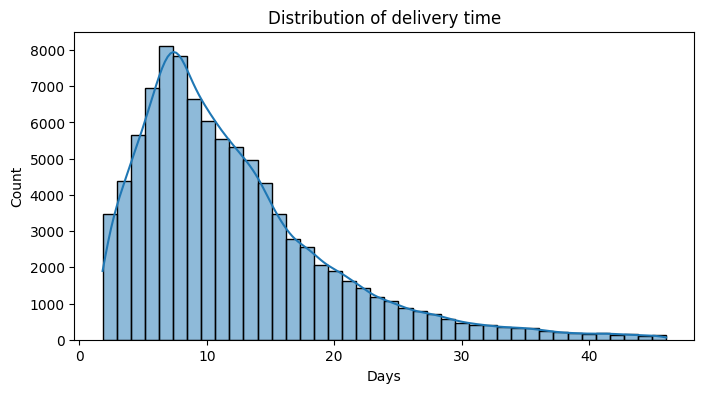

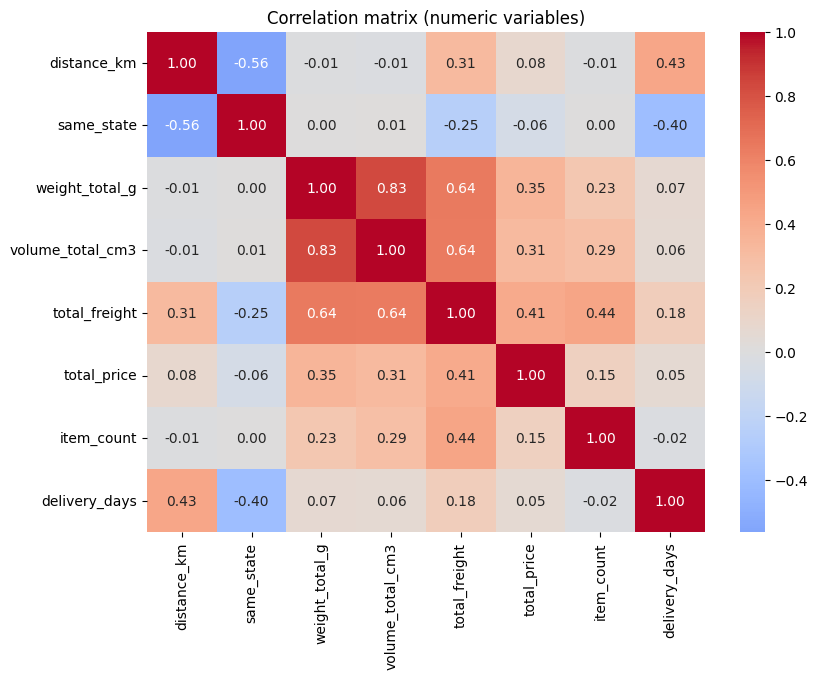

distance_km         0.434
same_state         -0.403
total_freight       0.181
weight_total_g      0.071
volume_total_cm3    0.063
total_price         0.054
item_count         -0.018
Name: delivery_days, dtype: float64


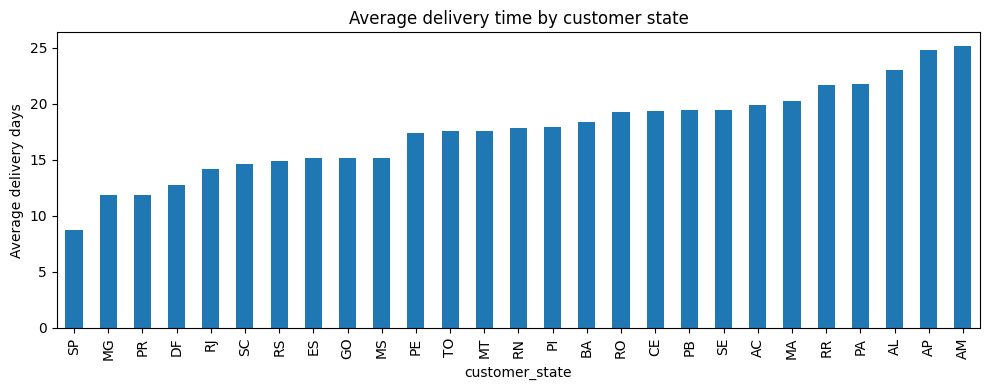

In [10]:
# Distribution of y
plt.figure(figsize=(8, 4))
sns.histplot(model_df['delivery_days'], bins=40, kde=True)
plt.title('Distribution of delivery time')
plt.xlabel('Days')
plt.savefig('figures/01_distribution_of_y.png', dpi=150, bbox_inches='tight')
plt.show()

# Correlation matrix of numeric variables (excluding one-hot columns)
corr_cols = numeric_features + ['delivery_days']
plt.figure(figsize=(9, 6.5))
sns.heatmap(model_df[corr_cols].corr(), annot=True, fmt='.2f', cmap='coolwarm', center=0)
plt.title('Correlation matrix (numeric variables)')
plt.savefig('figures/02_correlation_matrix.png', dpi=150, bbox_inches='tight')
plt.show()

print(model_df[corr_cols].corr()['delivery_days'].drop('delivery_days')
      .sort_values(key=abs, ascending=False).round(3))

# Average delivery time by customer state: the reason state needs one-hot encoding
state_mean = model_df.groupby('customer_state')['delivery_days'].mean().sort_values()
plt.figure(figsize=(10, 4))
state_mean.plot(kind='bar')
plt.ylabel('Average delivery days')
plt.title('Average delivery time by customer state')
plt.tight_layout()
plt.savefig('figures/03_delivery_time_by_state.png', dpi=150, bbox_inches='tight')
plt.show()

### Cell 8b: Average delivery time by customer state (numbers behind the bar chart)

In [11]:
state_stats = (model_df.groupby('customer_state')['delivery_days']
               .agg(['mean', 'count']).sort_values('mean'))
state_stats.columns = ['Mean delivery days', 'Orders']
state_stats.to_csv('figures/delivery_time_by_state.csv')
print(state_stats.round(2).to_string())

for s in ['SP', 'MG', 'AL', 'AP', 'AM']:
    print(f"{s}: {state_stats.loc[s, 'Mean delivery days']:.1f} days (n={state_stats.loc[s, 'Orders']})")
print(f"\nGap between the slowest and fastest state: "
      f"{state_stats['Mean delivery days'].max() - state_stats['Mean delivery days'].min():.1f} days")

                Mean delivery days  Orders
customer_state                            
SP                            8.74   39443
MG                           11.85   11243
PR                           11.86    4870
DF                           12.79    1900
RJ                           14.17   11931
SC                           14.62    3508
RS                           14.92    5270
ES                           15.12    1965
GO                           15.16    1923
MS                           15.18     691
PE                           17.36    1544
TO                           17.56     271
MT                           17.57     870
RN                           17.82     456
PI                           17.96     461
BA                           18.33    3176
RO                           19.26     239
CE                           19.35    1216
PB                           19.47     498
SE                           19.48     322
AC                           19.90      77
MA         

### Cell 9: Motivation for the problem - slow delivery means low reviews?
The review score exists only **after** the customer receives the order, so it is used here for illustration only and is **not put into X**.

                  mean  count
delivery_bucket              
<= 7 days        4.414  24897
7-14 days        4.312  39788
14-21 days       4.139  17469
21-28 days       3.687   6793
> 28 days        2.540   4518

Correlation between delivery_days and review_score: -0.309


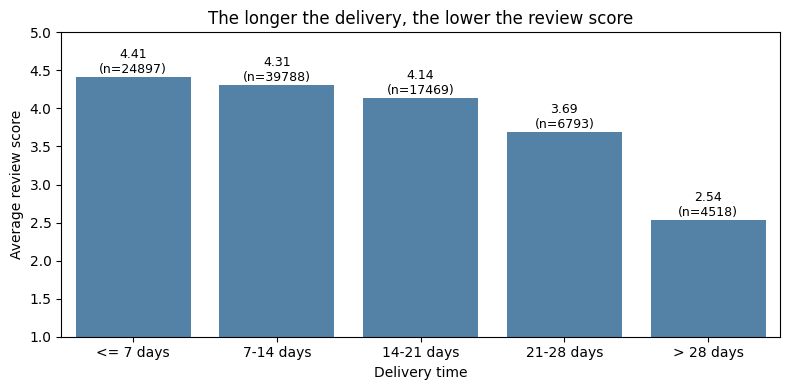

In [12]:
# Average review score per order (an order can have multiple reviews)
review_per_order = reviews.groupby('order_id')['review_score'].mean()

rev = model_df[['order_id', 'delivery_days']].copy()
rev['review_score'] = rev['order_id'].map(review_per_order)
rev = rev.dropna(subset=['review_score'])

# Split delivery time into buckets
bins = [0, 7, 14, 21, 28, np.inf]
labels = ['<= 7 days', '7-14 days', '14-21 days', '21-28 days', '> 28 days']
rev['delivery_bucket'] = pd.cut(rev['delivery_days'], bins=bins, labels=labels)
bucket_stats = rev.groupby('delivery_bucket', observed=True)['review_score'].agg(['mean', 'count'])
print(bucket_stats.round(3))
print("\nCorrelation between delivery_days and review_score:",
      round(rev['delivery_days'].corr(rev['review_score']), 3))

plt.figure(figsize=(8, 4))
ax = sns.barplot(x=bucket_stats.index.astype(str), y=bucket_stats['mean'].values, color='steelblue')
ax.set_ylim(1, 5)
ax.set_xlabel('Delivery time')
ax.set_ylabel('Average review score')
ax.set_title('The longer the delivery, the lower the review score')
for i, (m, c) in enumerate(zip(bucket_stats['mean'], bucket_stats['count'])):
    ax.text(i, m + 0.05, f"{m:.2f}\n(n={c})", ha='center', fontsize=9)
plt.tight_layout()
plt.savefig('figures/04_review_vs_delivery.png', dpi=150, bbox_inches='tight')
plt.show()

### Cell 10: Train/test split (80% / 20%)
Split **before** imputing missing values and standardizing, so that the test set does not influence any learned statistic.

In [13]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

print("X_train:", X_train.shape, "| X_test:", X_test.shape)
print("y_train:", y_train.shape, "| y_test:", y_test.shape)

X_train: (75260, 50) | X_test: (18815, 50)
y_train: (75260,) | y_test: (18815,)


### Cell 11: Choosing X - pairwise correlation and VIF
VIF measures how much a variable is explained by the other variables (VIF > 10 is a sign of severe multicollinearity). Computed on the **train set** (missing values imputed with the train median).
Selection rule: keep a variable if VIF <= 10; if a pair of variables is too highly correlated (|r| > 0.7), consider dropping one.

In [14]:
imp_diag = SimpleImputer(strategy='median').fit(X_train[numeric_features])
Xn = pd.DataFrame(imp_diag.transform(X_train[numeric_features]),
                  columns=numeric_features, index=X_train.index)

# Highly correlated variable pairs
corr_abs = Xn.corr().abs()
pairs = [(a, b, round(corr_abs.loc[a, b], 3))
         for i, a in enumerate(corr_abs.columns) for b in corr_abs.columns[i + 1:]
         if corr_abs.loc[a, b] > 0.7]
print("Variable pairs with |r| > 0.7:", pairs if pairs else "none")

# VIF
Xn_const = sm.add_constant(Xn)
vif = [variance_inflation_factor(Xn_const.values, i + 1) for i in range(len(numeric_features))]

selection = pd.DataFrame({
    'Variable': numeric_features,
    'Corr with y (train)': [Xn[c].corr(y_train) for c in numeric_features],
    'VIF': vif
})
selection['Decision'] = np.where(selection['VIF'] > 10, 'Consider dropping', 'Keep')
selection.to_csv('figures/x_selection_vif.csv', index=False)
print(selection.round(3).to_string(index=False))
# The one-hot variables (state, month, day of week) are categorical so VIF is not evaluated here.

Variable pairs with |r| > 0.7: [('weight_total_g', 'volume_total_cm3', np.float64(0.831))]
        Variable  Corr with y (train)   VIF Decision
     distance_km                0.434 1.657     Keep
      same_state               -0.404 1.498     Keep
  weight_total_g                0.071 3.616     Keep
volume_total_cm3                0.063 3.529     Keep
   total_freight                0.181 2.856     Keep
     total_price                0.054 1.230     Keep
      item_count               -0.017 1.311     Keep


## PART 3: Run the model
### Cell 12: Train Linear Regression (Pipeline), predict and compare with the baseline
The Pipeline consists of: median imputation (learned from train) → standardization → Linear Regression.

In [15]:
pipe = make_pipeline(SimpleImputer(strategy='median'),
                     StandardScaler(),
                     LinearRegression())

# Train on the train set
pipe.fit(X_train, y_train)

# Predict
y_pred_train = pipe.predict(X_train)
y_pred = pipe.predict(X_test)

# Baseline: always predict the mean of y_train
y_base = np.full(len(y_test), y_train.mean())

# Function to compute 3 metrics
def evaluate(y_true, y_hat):
    return {
        'MAE': mean_absolute_error(y_true, y_hat),
        'RMSE': np.sqrt(mean_squared_error(y_true, y_hat)),
        'R2': r2_score(y_true, y_hat)
    }

results = pd.DataFrame({
    'Baseline (test)': evaluate(y_test, y_base),
    'Linear Regression (train)': evaluate(y_train, y_pred_train),
    'Linear Regression (test)': evaluate(y_test, y_pred)
}).T
print(results.round(3))
# Train and test are close -> the model is not overfitting

                             MAE   RMSE     R2
Baseline (test)            5.803  7.700 -0.000
Linear Regression (train)  4.599  6.324  0.326
Linear Regression (test)   4.651  6.349  0.320


### Cell 13: Model comparison
Includes 2 baselines (global mean, mean by customer state) and Linear Regression, evaluated on the same test set.

                            MAE   RMSE     R2
Baseline (mean)           5.803  7.700 -0.000
Baseline (mean by state)  5.062  6.855  0.207
Linear Regression         4.651  6.349  0.320


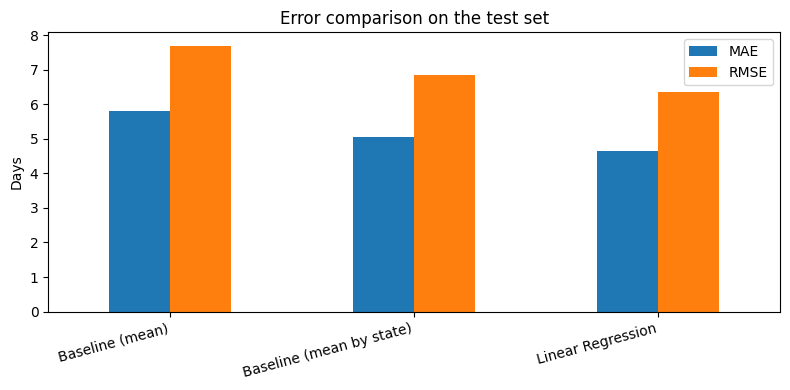

In [16]:
# Baseline 2: average delivery time by customer state (learned from train)
state_train = model_df.loc[X_train.index, 'customer_state']
state_test = model_df.loc[X_test.index, 'customer_state']
state_mean_train = y_train.groupby(state_train).mean()
y_base_state = state_test.map(state_mean_train).fillna(y_train.mean()).values

results_all = pd.DataFrame({
    'Baseline (mean)': evaluate(y_test, y_base),
    'Baseline (mean by state)': evaluate(y_test, y_base_state),
    'Linear Regression': evaluate(y_test, y_pred)
}).T
results_all.to_csv('figures/model_comparison.csv')
print(results_all.round(3))

results_all[['MAE', 'RMSE']].plot(kind='bar', figsize=(8, 4))
plt.ylabel('Days')
plt.title('Error comparison on the test set')
plt.xticks(rotation=15, ha='right')
plt.tight_layout()
plt.savefig('figures/05_model_comparison.png', dpi=150, bbox_inches='tight')
plt.show()

### Cell 13b: Share of predictions within 3 / 5 days, and relative improvement over the baselines

In [17]:
actual = y_test.to_numpy()
preds = {'Baseline (mean)': np.asarray(y_base),
         'Baseline (mean by state)': np.asarray(y_base_state),
         'Linear Regression': np.asarray(y_pred)}

tolerance = pd.DataFrame({
    name: {'Within 3 days': (np.abs(actual - yh) <= 3).mean(),
           'Within 5 days': (np.abs(actual - yh) <= 5).mean()}
    for name, yh in preds.items()}).T
tolerance.to_csv('figures/error_tolerance.csv')
print((tolerance * 100).round(1).astype(str) + '%')

# Relative improvement of Linear Regression over each baseline
print()
for ref in ['Baseline (mean)', 'Baseline (mean by state)']:
    for m in ['MAE', 'RMSE']:
        a, b = results_all.loc['Linear Regression', m], results_all.loc[ref, m]
        print(f"{m} vs {ref}: {b - a:.3f} lower ({1 - a / b:.1%})")

mae_lr = results_all.loc['Linear Regression', 'MAE']
print(f"\nMAE / mean delivery time (test): {mae_lr:.3f} / {y_test.mean():.2f} = {mae_lr / y_test.mean():.1%}")
print(f"Unexplained variation (1 - R2): {1 - results_all.loc['Linear Regression', 'R2']:.1%}")

                         Within 3 days Within 5 days
Baseline (mean)                  31.1%         52.1%
Baseline (mean by state)         38.1%         61.0%
Linear Regression                42.4%         65.4%

MAE vs Baseline (mean): 1.152 lower (19.9%)
RMSE vs Baseline (mean): 1.351 lower (17.5%)
MAE vs Baseline (mean by state): 0.411 lower (8.1%)
RMSE vs Baseline (mean by state): 0.506 lower (7.4%)

MAE / mean delivery time (test): 4.651 / 12.21 = 38.1%
Unexplained variation (1 - R2): 68.0%


### Cell 14: Model checking - Residual plot and Q-Q plot

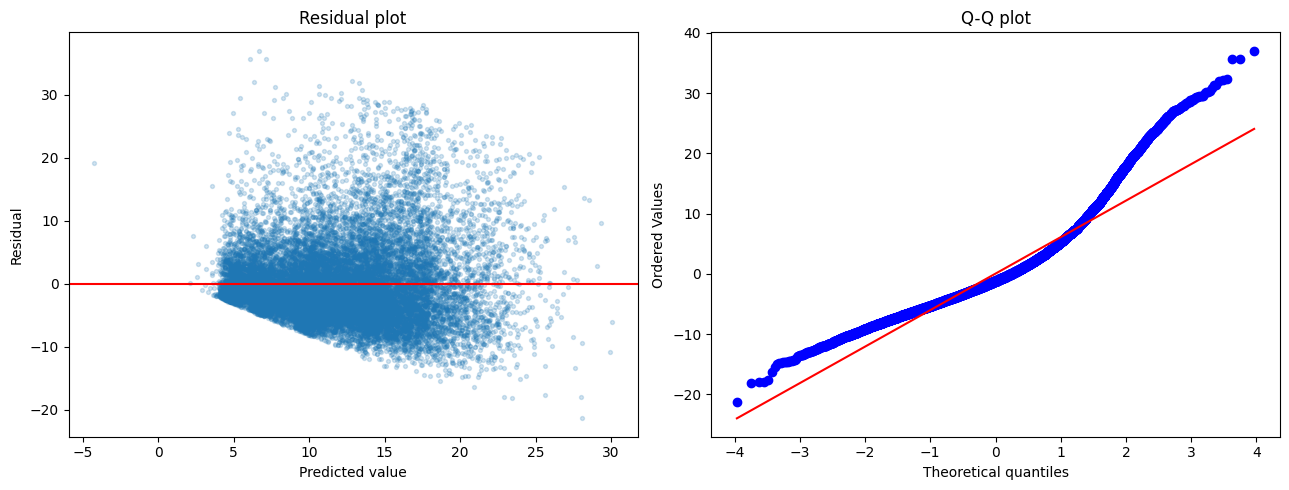

In [18]:
residual = y_test - y_pred      # residual = actual - predicted

fig, axes = plt.subplots(1, 2, figsize=(13, 5))

# Residual plot: residuals should be scattered evenly around 0 with no particular pattern
axes[0].scatter(y_pred, residual, alpha=0.2, s=8)
axes[0].axhline(0, color='red')
axes[0].set_title('Residual plot')
axes[0].set_xlabel('Predicted value')
axes[0].set_ylabel('Residual')

# Q-Q plot: the closer the points are to the straight line, the closer the residuals are to a normal distribution
stats.probplot(residual, dist='norm', plot=axes[1])
axes[1].set_title('Q-Q plot')

plt.tight_layout()
fig.savefig('figures/07_residual_qq.png', dpi=150, bbox_inches='tight')   # save both plots
# Save each plot separately
fig.canvas.draw()
for ax, name in zip(axes, ['08_residual_plot', '09_qq_plot']):
    ext = ax.get_tightbbox(fig.canvas.get_renderer()).transformed(fig.dpi_scale_trans.inverted())
    fig.savefig(f'figures/{name}.png', dpi=150, bbox_inches=ext.expanded(1.05, 1.1))
plt.show()

### Cell 14b: Residual statistics (numbers behind Residual plot and Q-Q plot)

In [19]:
res = np.asarray(residual)
pred_t = np.asarray(y_pred)

print(f"Share of negative residuals: {(res < 0).mean():.1%}")
print(f"Median residual: {np.median(res):.2f} | min: {res.min():.1f} | max: {res.max():.1f}")
print(f"Skewness: {stats.skew(res):.2f} | excess kurtosis: {stats.kurtosis(res):.2f}")

# Spread of residuals by predicted-value range (heteroscedasticity)
for lo, hi in [(5, 8), (12, 18)]:
    m = (pred_t >= lo) & (pred_t <= hi)
    if m.sum() == 0:
        print(f"Predictions {lo}-{hi} days: no test orders")
        continue
    p1, p99 = np.percentile(res[m], [1, 99])
    print(f"Predictions {lo}-{hi} days (n={m.sum()}): std = {res[m].std():.1f}, "
          f"98% of residuals in [{p1:.1f}, {p99:.1f}]")

# Lower boundary: y was trimmed at `low`, so residual >= low - prediction
print(f"\nLower trimming bound of y: {low:.2f} days | min y_test: {y_test.min():.2f} days")

Share of negative residuals: 59.6%
Median residual: -1.20 | min: -21.3 | max: 37.0
Skewness: 1.38 | excess kurtosis: 2.93
Predictions 5-8 days (n=2936): std = 4.7, 98% of residuals in [-5.1, 18.7]
Predictions 12-18 days (n=7504): std = 7.2, 98% of residuals in [-10.6, 24.3]

Lower trimming bound of y: 1.83 days | min y_test: 1.83 days


### Cell 15: Predicted vs actual
The closer the points are to the red diagonal line, the more accurate the predictions.

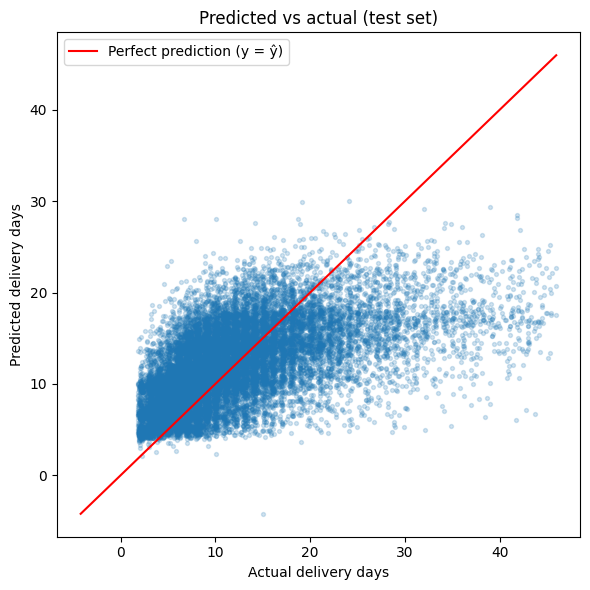

In [20]:
plt.figure(figsize=(6, 6))
plt.scatter(y_test, y_pred, alpha=0.2, s=8)
lim = [min(y_test.min(), y_pred.min()), max(y_test.max(), y_pred.max())]
plt.plot(lim, lim, color='red', label='Perfect prediction (y = ŷ)')
plt.xlabel('Actual delivery days')
plt.ylabel('Predicted delivery days')
plt.title('Predicted vs actual (test set)')
plt.legend()
plt.tight_layout()
plt.savefig('figures/06_predicted_vs_actual.png', dpi=150, bbox_inches='tight')
plt.show()

### Cell 15b: Numbers behind the Predicted vs actual plot
Short deliveries are overestimated, long deliveries are underestimated.

In [21]:
actual = y_test.to_numpy()
pred_t = np.asarray(y_pred)

# Short deliveries (actual <= 5 days)
short = actual <= 5
print(f"Actual <= 5 days: {short.sum()} test orders | mean actual {actual[short].mean():.1f} | "
      f"mean predicted {pred_t[short].mean():.1f} | overestimated: {(pred_t[short] > actual[short]).mean():.1%}")

# Long deliveries (actual > 30 days)
long_ = actual > 30
p5, p95 = np.percentile(pred_t[long_], [5, 95])
print(f"Actual > 30 days: {long_.sum()} test orders | mean actual {actual[long_].mean():.1f} | "
      f"mean predicted {pred_t[long_].mean():.1f} | MAE {np.abs(actual[long_] - pred_t[long_]).mean():.1f} | "
      f"predicted 5th-95th percentile: {p5:.0f} to {p95:.0f} days")

# Range of predictions
print(f"\nPredictions > 25 days: {(pred_t > 25).sum()} of {len(pred_t)} test orders")
print(f"Lowest prediction: {pred_t.min():.2f} days | negative predictions: {(pred_t < 0).sum()}")

Actual <= 5 days: 2452 test orders | mean actual 3.6 | mean predicted 7.9 | overestimated: 98.6%
Actual > 30 days: 715 test orders | mean actual 36.0 | mean predicted 17.4 | MAE 18.6 | predicted 5th-95th percentile: 11 to 24 days

Predictions > 25 days: 56 of 18815 test orders
Lowest prediction: -4.22 days | negative predictions: 1


### Cell 16: Interpreting the coefficients b
Because the variables are standardized, the model gives coefficients in units of standard deviation (the magnitudes are comparable across variables). Below they are converted back to **original units** (days per km, per gram, ...) for easier interpretation.

In [22]:
scaler = pipe.named_steps['standardscaler']
lin = pipe.named_steps['linearregression']

coef_std = lin.coef_                         # change in days when the variable increases by 1 standard deviation
coef_raw = lin.coef_ / scaler.scale_         # change in days when the variable increases by 1 original unit
intercept_raw = lin.intercept_ - np.sum(coef_raw * scaler.mean_)

coef_table = pd.DataFrame({
    'Variable': X.columns,
    'b (per 1 std)': coef_std,
    'b (original unit)': coef_raw
}).sort_values('b (per 1 std)', key=abs, ascending=False)

print("Intercept b0 (original unit):", round(intercept_raw, 3))
print(coef_table.head(15).round(4).to_string(index=False))

# How to read: holding the other variables constant, when x increases by 1 original unit, the delivery time changes by b days.
# - For one-hot variables (state_*, month_*, dow_*), b is the difference in days relative to the dropped reference level.
# - The coefficients only describe association, not causation.
# - The 2016-2018 data has seasonal effects (e.g. Black Friday 11/2017, the 2018 trucker strike),
#   so the coefficients of the month_* variables should be mentioned in the discussion section.

Intercept b0 (original unit): 13.111
      Variable  b (per 1 std)  b (original unit)
   distance_km         1.7197             0.0029
    same_state        -1.2740            -2.6593
       month_8        -1.1866            -3.8014
       month_7        -1.0536            -3.4382
      state_SP        -1.0265            -2.0799
       month_6        -0.9324            -3.1698
       month_5        -0.5540            -1.7960
      state_MG        -0.5212            -1.6048
       month_2         0.4962             1.7897
weight_total_g         0.4387             0.0001
      state_BA         0.4319             2.3719
       month_9        -0.3940            -1.9308
         dow_4         0.3896             1.1154
      month_12         0.3604             1.5598
       month_4        -0.3593            -1.2286


### Cell 16b: Coefficients in more detail and Figure 10 (top 15 coefficients)
- Original-unit coefficients printed with more decimals (small values such as weight or price were rounded to 0.0001).
- Coefficients of all customer states, reference levels, and ranking by original-unit effect.
- Chart of the top 15 standardized coefficients.

Numeric coefficients (original unit, 6 decimals):
distance_km          0.002922
same_state          -2.659273
weight_total_g       0.000092
volume_total_cm3     0.000009
total_freight       -0.003070
total_price         -0.000284
item_count          -0.501294

distance_km : +0.29 days per 100 km
weight_total_g: +0.092 days per kg
total_price : -0.28 days per 1,000 BRL
item_count  : -0.501 days per extra item

Reference levels: state = AC, month = 1, day of week = 0 (Monday)

State coefficients (relative to AC):
          b (original unit)  b (per 1 std)  Orders
state_AM             5.5763         0.2262     141
state_AL             5.3506         0.3377     376
state_AP             4.6846         0.1219      66
state_PA             2.9350         0.2843     893
state_BA             2.3719         0.4319    3176
state_SE             2.2919         0.1332     322
state_MA             1.9521         0.1657     689
state_MT             1.4967         0.1436     870
state_PB             1.2

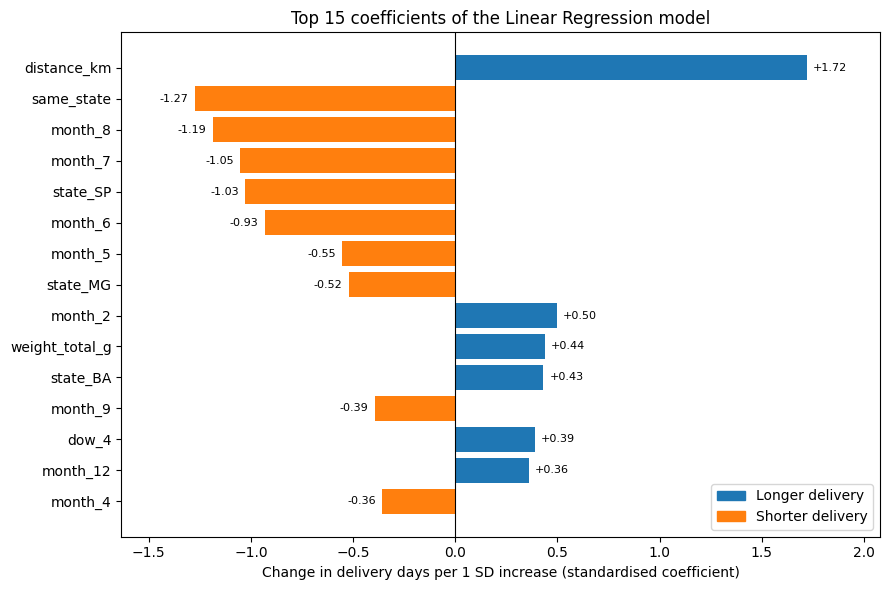

In [23]:
from matplotlib.patches import Patch

coef_raw_s = pd.Series(coef_raw, index=X.columns)
coef_std_s = pd.Series(coef_std, index=X.columns)

# 1) Numeric variables with more decimals + readable units
print("Numeric coefficients (original unit, 6 decimals):")
print(coef_raw_s[numeric_features].map('{:.6f}'.format).to_string())
print(f"\ndistance_km : {coef_raw_s['distance_km'] * 100:+.2f} days per 100 km")
print(f"weight_total_g: {coef_raw_s['weight_total_g'] * 1000:+.3f} days per kg")
print(f"total_price : {coef_raw_s['total_price'] * 1000:+.2f} days per 1,000 BRL")
print(f"item_count  : {coef_raw_s['item_count']:+.3f} days per extra item")

# 2) Reference levels of the one-hot variables (the dropped level)
ref_state = sorted(model_df['customer_state'].unique())[0]
print(f"\nReference levels: state = {ref_state}, month = {model_df['purchase_month'].min()}, "
      f"day of week = {model_df['purchase_dayofweek'].min()} (Monday)")

# 3) All customer-state coefficients (original unit, days relative to the reference state)
state_counts = model_df['customer_state'].value_counts()
state_coef = pd.DataFrame({
    'b (original unit)': coef_raw_s[[c for c in X.columns if c.startswith('state_')]],
    'b (per 1 std)': coef_std_s[[c for c in X.columns if c.startswith('state_')]]})
state_coef['Orders'] = [state_counts.get(c.replace('state_', ''), 0) for c in state_coef.index]
state_coef = state_coef.sort_values('b (original unit)', ascending=False)
state_coef.to_csv('figures/state_coefficients.csv')
print(f"\nState coefficients (relative to {ref_state}):")
print(state_coef.round(4).to_string())

# 4) Ranking by original-unit effect (dummies and same_state only, numeric per-unit values are not comparable)
rank_raw = (coef_table[coef_table['Variable'].str.contains('state|month_|dow_')]
            .assign(abs_raw=lambda d: d['b (original unit)'].abs())
            .sort_values('abs_raw', ascending=False).head(10))
print("\nTop 10 by |original-unit effect| (same_state and dummies):")
print(rank_raw[['Variable', 'b (per 1 std)', 'b (original unit)']].round(4).to_string(index=False))

# 5) Figure 10: top 15 standardized coefficients
top15 = coef_table.head(15).iloc[::-1]                 # reversed so that rank 1 is at the top
colors = ['#1f77b4' if v > 0 else '#ff7f0e' for v in top15['b (per 1 std)']]
fig, ax = plt.subplots(figsize=(9, 6))
ax.barh(top15['Variable'], top15['b (per 1 std)'], color=colors)
ax.axvline(0, color='black', linewidth=0.8)
for i, v in enumerate(top15['b (per 1 std)']):
    ax.text(v + (0.03 if v > 0 else -0.03), i, f'{v:+.2f}', va='center',
            ha='left' if v > 0 else 'right', fontsize=8)
ax.margins(x=0.12)
ax.set_xlabel('Change in delivery days per 1 SD increase (standardised coefficient)')
ax.set_title('Top 15 coefficients of the Linear Regression model')
ax.legend(handles=[Patch(color='#1f77b4', label='Longer delivery'),
                   Patch(color='#ff7f0e', label='Shorter delivery')], loc='lower right')
plt.tight_layout()
plt.savefig('figures/10_top15_coefficients.png', dpi=150, bbox_inches='tight')
plt.show()

### Cell 17: p-values and confidence intervals of the coefficients (statsmodels OLS)
Run OLS on the train set (missing values imputed with the train median), in original units, to see which coefficients are statistically significant.

In [24]:
imp_final = pipe.named_steps['simpleimputer']
X_train_imp = pd.DataFrame(imp_final.transform(X_train), columns=X_train.columns, index=X_train.index)

ols = sm.OLS(y_train, sm.add_constant(X_train_imp)).fit()
ci = ols.conf_int()
ols_table = pd.DataFrame({
    'b': ols.params,
    'CI 2.5%': ci[0],
    'CI 97.5%': ci[1],
    'p-value': ols.pvalues
})
ols_table['Significant (p<0.05)'] = ols_table['p-value'] < 0.05
ols_table.to_csv('figures/ols_coefficients.csv')

print(f"R2 (train, OLS): {ols.rsquared:.3f}")
print(f"Number of statistically significant coefficients: {ols_table['Significant (p<0.05)'].sum()} / {len(ols_table)}\n")
print(ols_table.loc[['const'] + numeric_features].round(4).to_string())

R2 (train, OLS): 0.326
Number of statistically significant coefficients: 30 / 51

                        b  CI 2.5%  CI 97.5%  p-value  Significant (p<0.05)
const             13.1114  11.3519   14.8709   0.0000                  True
distance_km        0.0029   0.0027    0.0031   0.0000                  True
same_state        -2.6593  -2.8127   -2.5058   0.0000                  True
weight_total_g     0.0001   0.0001    0.0001   0.0000                  True
volume_total_cm3   0.0000   0.0000    0.0000   0.0000                  True
total_freight     -0.0031  -0.0067    0.0005   0.0929                 False
total_price       -0.0003  -0.0005   -0.0000   0.0237                  True
item_count        -0.5013  -0.5976   -0.4049   0.0000                  True


### Cell 17b: Heteroscedasticity test (Breusch-Pagan) and robust standard errors (HC3)
- Breusch-Pagan on the **train** residuals: H0 = constant error variance.
- HC3 re-estimates the standard errors of the same OLS model, so coefficients are unchanged but p-values and confidence intervals are heteroscedasticity-robust.

In [25]:
from statsmodels.stats.diagnostic import het_breuschpagan

# 1) Breusch-Pagan test on the training residuals
lm, lm_p, f_stat, f_p = het_breuschpagan(ols.resid, ols.model.exog)
print(f"Breusch-Pagan: LM = {lm:.0f}, p = {lm_p:.3g} | F = {f_stat:.1f}, p = {f_p:.3g}")

# 2) Same OLS with HC3 robust standard errors
ols_hc3 = sm.OLS(y_train, sm.add_constant(X_train_imp)).fit(cov_type='HC3')
ci3 = ols_hc3.conf_int()
hc3_table = pd.DataFrame({
    'b': ols_hc3.params,
    'CI 2.5% (HC3)': ci3[0],
    'CI 97.5% (HC3)': ci3[1],
    'p-value (classical)': ols.pvalues,
    'p-value (HC3)': ols_hc3.pvalues
})
hc3_table['Significant (classical)'] = hc3_table['p-value (classical)'] < 0.05
hc3_table['Significant (HC3)'] = hc3_table['p-value (HC3)'] < 0.05
hc3_table.to_csv('figures/ols_coefficients_hc3.csv')

print(f"\nSignificant at 5% - classical: {hc3_table['Significant (classical)'].sum()} / {len(hc3_table)}")
print(f"Significant at 5% - HC3      : {hc3_table['Significant (HC3)'].sum()} / {len(hc3_table)}")

changed = hc3_table[hc3_table['Significant (classical)'] != hc3_table['Significant (HC3)']]
print("\nCoefficients whose significance changes with HC3:")
print(changed[['p-value (classical)', 'p-value (HC3)']].round(4).to_string() if len(changed) else "none")

print("\nNumeric predictors (classical vs HC3):")
print(hc3_table.loc[['const'] + numeric_features,
                    ['b', 'p-value (classical)', 'p-value (HC3)']].round(4).to_string())
print(f"\ntotal_price p (HC3) = {hc3_table.loc['total_price', 'p-value (HC3)']:.3f} | "
      f"total_freight p (HC3) = {hc3_table.loc['total_freight', 'p-value (HC3)']:.3f}")

Breusch-Pagan: LM = 3668, p = 0 | F = 77.1, p = 0

Significant at 5% - classical: 30 / 51
Significant at 5% - HC3      : 29 / 51

Coefficients whose significance changes with HC3:
             p-value (classical)  p-value (HC3)
total_price               0.0237         0.0528

Numeric predictors (classical vs HC3):
                        b  p-value (classical)  p-value (HC3)
const             13.1114               0.0000         0.0000
distance_km        0.0029               0.0000         0.0000
same_state        -2.6593               0.0000         0.0000
weight_total_g     0.0001               0.0000         0.0000
volume_total_cm3   0.0000               0.0000         0.0000
total_freight     -0.0031               0.0929         0.2549
total_price       -0.0003               0.0237         0.0528
item_count        -0.5013               0.0000         0.0000

total_price p (HC3) = 0.053 | total_freight p (HC3) = 0.255


### Cell 18: Zip the figures folder for download

In [26]:
import shutil
shutil.make_archive('figures', 'zip', 'figures')
print("Created figures.zip containing:", sorted(os.listdir('figures')))

# On Colab: download the zip file to your machine
try:
    from google.colab import files
    files.download('figures.zip')
except ImportError:
    print("Not running on Colab: get figures.zip from the working directory.")

Created figures.zip containing: ['01_distribution_of_y.png', '02_correlation_matrix.png', '03_delivery_time_by_state.png', '04_review_vs_delivery.png', '05_model_comparison.png', '06_predicted_vs_actual.png', '07_residual_qq.png', '08_residual_plot.png', '09_qq_plot.png', '10_top15_coefficients.png', 'cleaning_table.csv', 'delivery_time_by_state.csv', 'error_tolerance.csv', 'model_comparison.csv', 'ols_coefficients.csv', 'ols_coefficients_hc3.csv', 'state_coefficients.csv', 'table1_raw_tables.csv', 'x_selection_vif.csv']
Not running on Colab: get figures.zip from the working directory.
